# Auto-Rickshaw Trip Analysis

Generate 600 fictional Ahmedabad auto-rickshaw trips with seed 42 and create four charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path.cwd()


## 1. Generate trips and plot daily total fare

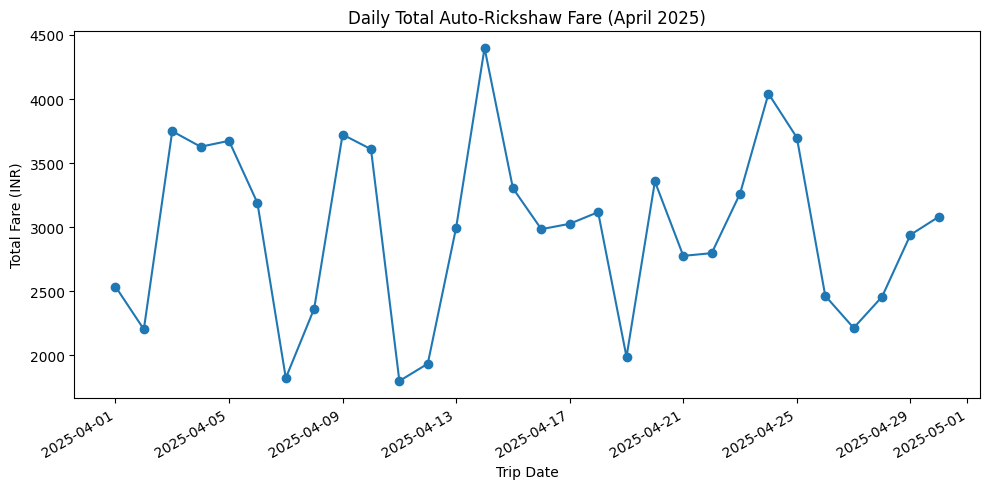

In [2]:
rng = np.random.default_rng(42)
n = 600
dates = pd.Timestamp("2025-04-01") + pd.to_timedelta(rng.integers(0, 30, n), unit="D")
distance = rng.integers(1, 16, n)
noise = rng.integers(-15, 26, n)
df = pd.DataFrame({
    "trip_id": np.arange(1, n + 1),
    "trip_date": pd.to_datetime(dates),
    "area": rng.choice(["Navrangpura", "Maninagar", "Satellite", "Vastrapur", "Paldi"], n),
    "distance_km": distance,
    "fare_inr": np.rint(30 + 14 * distance + noise).astype(int)
})
df.to_csv(OUTPUT_DIR / "auto_trips.csv", index=False)
daily_fare = df.set_index("trip_date").resample("D")["fare_inr"].sum()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(daily_fare.index, daily_fare.values, marker="o")
ax.set_title("Daily Total Auto-Rickshaw Fare (April 2025)")
ax.set_xlabel("Trip Date")
ax.set_ylabel("Total Fare (INR)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "daily_fare_line.png", dpi=150, bbox_inches="tight")
plt.show()


## 2. Scatter plot: distance versus fare

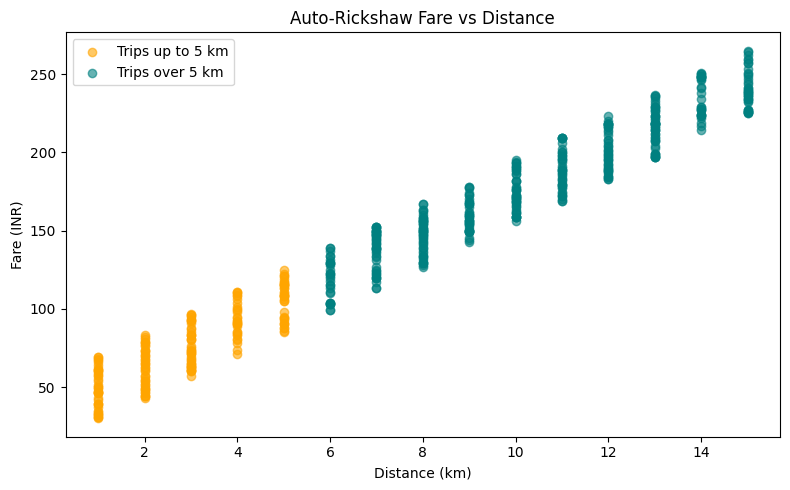

In [3]:
short = df[df["distance_km"] <= 5]
long = df[df["distance_km"] > 5]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(short["distance_km"], short["fare_inr"], color="orange", alpha=0.6, label="Trips up to 5 km")
ax.scatter(long["distance_km"], long["fare_inr"], color="teal", alpha=0.6, label="Trips over 5 km")
ax.set_title("Auto-Rickshaw Fare vs Distance")
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Fare (INR)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fare_vs_distance.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Bar chart: trips per area

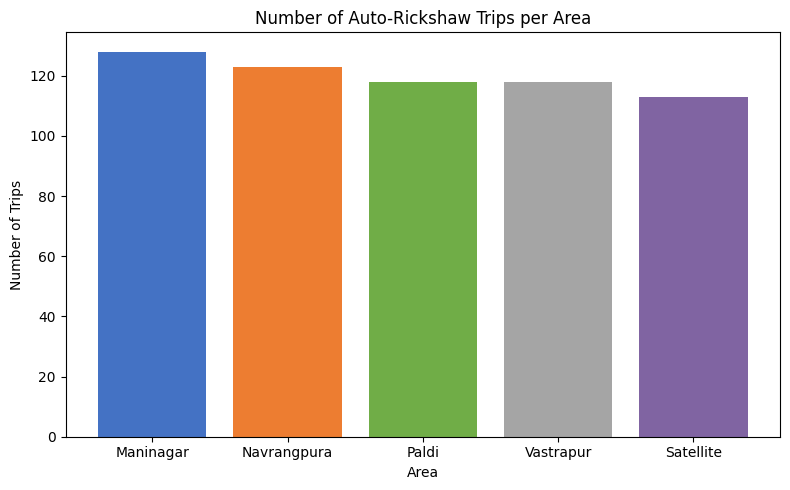

area
Maninagar      128
Navrangpura    123
Paldi          118
Vastrapur      118
Satellite      113
Name: count, dtype: int64


In [4]:
area_counts = df["area"].value_counts().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#4472C4", "#ED7D31", "#70AD47", "#A5A5A5", "#8064A2"]
ax.bar(area_counts.index, area_counts.values, color=colors[:len(area_counts)])
ax.set_title("Number of Auto-Rickshaw Trips per Area")
ax.set_xlabel("Area")
ax.set_ylabel("Number of Trips")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "trips_per_area.png", dpi=150, bbox_inches="tight")
plt.show()
print(area_counts)


## 4. Fare histogram and file verification

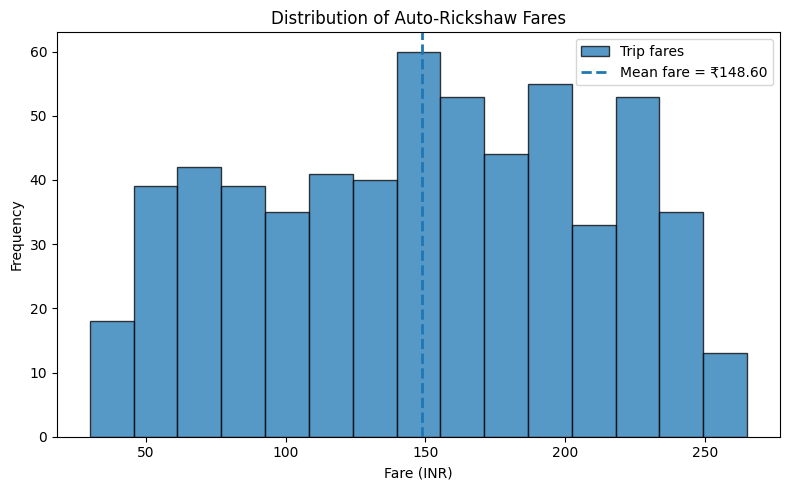

daily_fare_line.png exists: True
fare_vs_distance.png exists: True
trips_per_area.png exists: True
fare_hist.png exists: True


In [5]:
mean_fare = df["fare_inr"].mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["fare_inr"], bins=15, edgecolor="black", alpha=0.75, label="Trip fares")
ax.axvline(mean_fare, linestyle="--", linewidth=2, label=f"Mean fare = ₹{mean_fare:.2f}")
ax.set_title("Distribution of Auto-Rickshaw Fares")
ax.set_xlabel("Fare (INR)")
ax.set_ylabel("Frequency")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fare_hist.png", dpi=150, bbox_inches="tight")
plt.show()

required = ["daily_fare_line.png", "fare_vs_distance.png", "trips_per_area.png", "fare_hist.png"]
for filename in required:
    print(filename, "exists:", (OUTPUT_DIR / filename).exists())
